# Stage 4 · Scaling law on measured single-GPU runs

75 real runs: 5 model sizes × 5 data budgets × 3 seeds. Models reuse stage-two GPT; stage-one BPE is loaded from stage three. All multi-GPU tasks are cancelled.

Fit on the smaller 4×4 cells only; hold out every largest-N/largest-D cell. D counts distinct positions, while training uses two epochs. Fixed validation tokens are separated before choosing training subsets.

In [1]:
from pathlib import Path
import sys, json, csv
from IPython.display import display, Image
STAGE = Path.cwd() if (Path.cwd()/'config.json').exists() else Path.cwd().parent
sys.path.insert(0,str(STAGE/'scripts'))
from fit_scaling import main as fit
result = fit()


{
  "protocol": "2 epochs, fixed BF16 GPT training protocol; D and compute covary",
  "model_parameters": [
    141056,
    285312,
    676992,
    1457856,
    3323392
  ],
  "data_budgets": [
    8192,
    16384,
    32768,
    65536,
    131072
  ],
  "seeds": [
    1337,
    2026,
    42
  ],
  "sample_count": 75,
  "training_cells": 16,
  "held_out_cells": 9,
  "normalization": {
    "N0": 1000000.0,
    "D0": 65536
  },
  "joint_form": "L(N,D)=E + A*(N/1e6)^(-alpha) + B*(D/65536)^(-beta)",
  "coefficients": {
    "E": 4.233112442581382e-22,
    "A": 0.6649710035546224,
    "alpha": 0.3533363965297309,
    "B": 2.676389054911062,
    "beta": 0.21817458347266303
  },
  "coefficient_seed_bootstrap_95pct": {
    "E": [
      1.2089950064353027e-27,
      9.159043828109833e-15
    ],
    "A": [
      0.5285893776255642,
      0.7649012751206152
    ],
    "alpha": [
      0.3167163981929842,
      0.42045443916708464
    ],
    "B": [
      2.576157950745965,
      2.8167998869275963


## Coefficients and normalization

Joint model: `L=E + A*(N/1e6)^(-alpha) + B*(D/65536)^(-beta)`. One-dimensional fits hold D or N fixed. Coefficients and seed-only bootstrap intervals are printed below. The E boundary warning must be retained; it prevents interpreting the fitted floor physically.

In [2]:
display(result['coefficients'])
display(result['coefficient_seed_bootstrap_95pct'])
display(result['one_dimensional'])
print(result['coefficient_boundary_note'])

{'E': 4.233112442581382e-22,
 'A': 0.6649710035546224,
 'alpha': 0.3533363965297309,
 'B': 2.676389054911062,
 'beta': 0.21817458347266303}

{'E': [1.2089950064353027e-27, 9.159043828109833e-15],
 'A': [0.5285893776255642, 0.7649012751206152],
 'alpha': [0.3167163981929842, 0.42045443916708464],
 'B': [2.576157950745965, 2.8167998869275963],
 'beta': [0.2087435409537967, 0.22583710125448983]}

{'N': {'form': 'E + A*(x/x0)^(-alpha)',
  'x0': 1000000.0,
  'coefficients': {'E': 3.3053941953107144,
   'A': 0.07770362167346476,
   'alpha': 1.0822386297602675},
  'fixed_axis_value': 65536,
  'fitted_sizes': [141056, 285312, 676992, 1457856],
  'held_out_size': 3323392,
  'held_out_observed_loss': 3.3311236194832614,
  'held_out_predicted_loss': 3.3265761257492987,
  'held_out_relative_error': 0.0013651530995022361},
 'D': {'form': 'E + A*(x/x0)^(-alpha)',
  'x0': 65536.0,
  'coefficients': {'E': 1.9417135652114128,
   'A': 1.4004803149197311,
   'alpha': 0.32488734865642854},
  'fixed_axis_value': 1457856,
  'fitted_sizes': [8192, 16384, 32768, 65536],
  'held_out_size': 131072,
  'held_out_observed_loss': 3.1591908099159363,
  'held_out_predicted_loss': 3.0598020421048533,
  'held_out_relative_error': 0.03146019781366977}}

E reached its nonnegative boundary; this data does not identify a physical irreducible loss floor.


## Local extrapolation check

Maximum parameter count and maximum data budget were never used to estimate coefficients. The preregistered gate is **mean** absolute relative error ≤10%; maximum error is reported separately. Passing the mean gate is not a bound on every prediction.

{'training_cells': 16,
 'held_out_cells': 9,
 'fit_rmse': 0.05599518037810687,
 'holdout_mape': 0.051737677431750104,
 'holdout_max_relative_error': 0.1303999556103505,
 'local_mape_gate_passed': True}

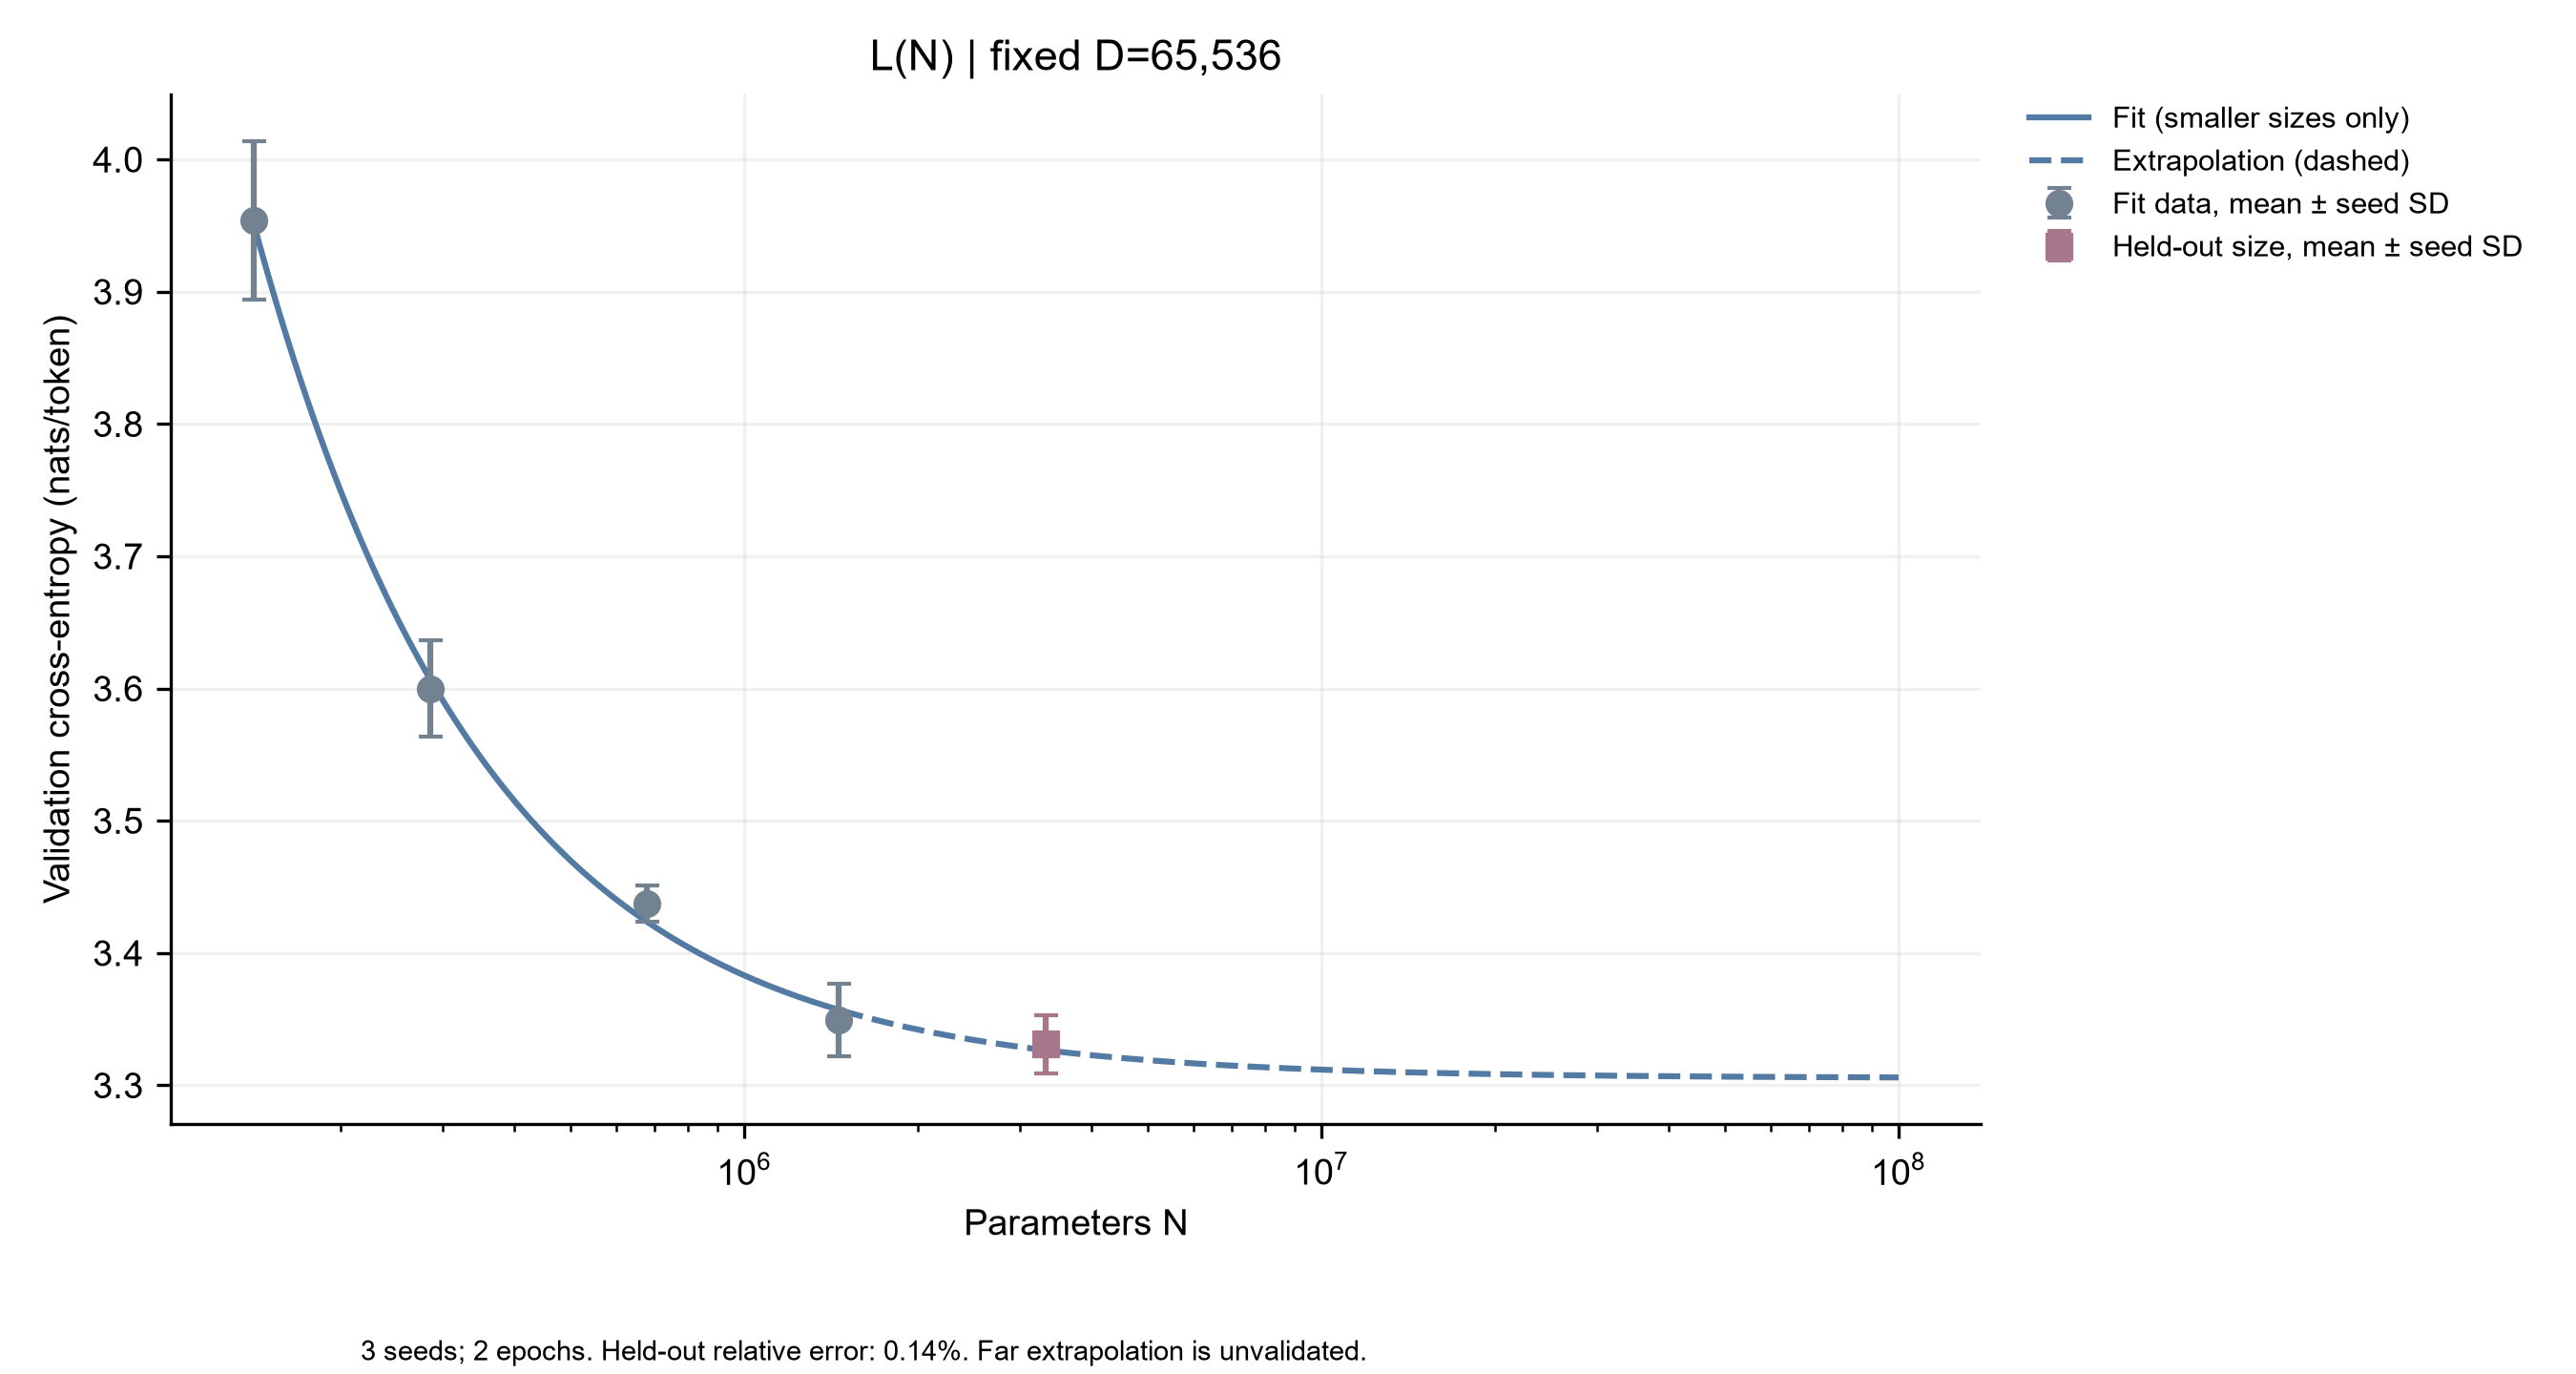

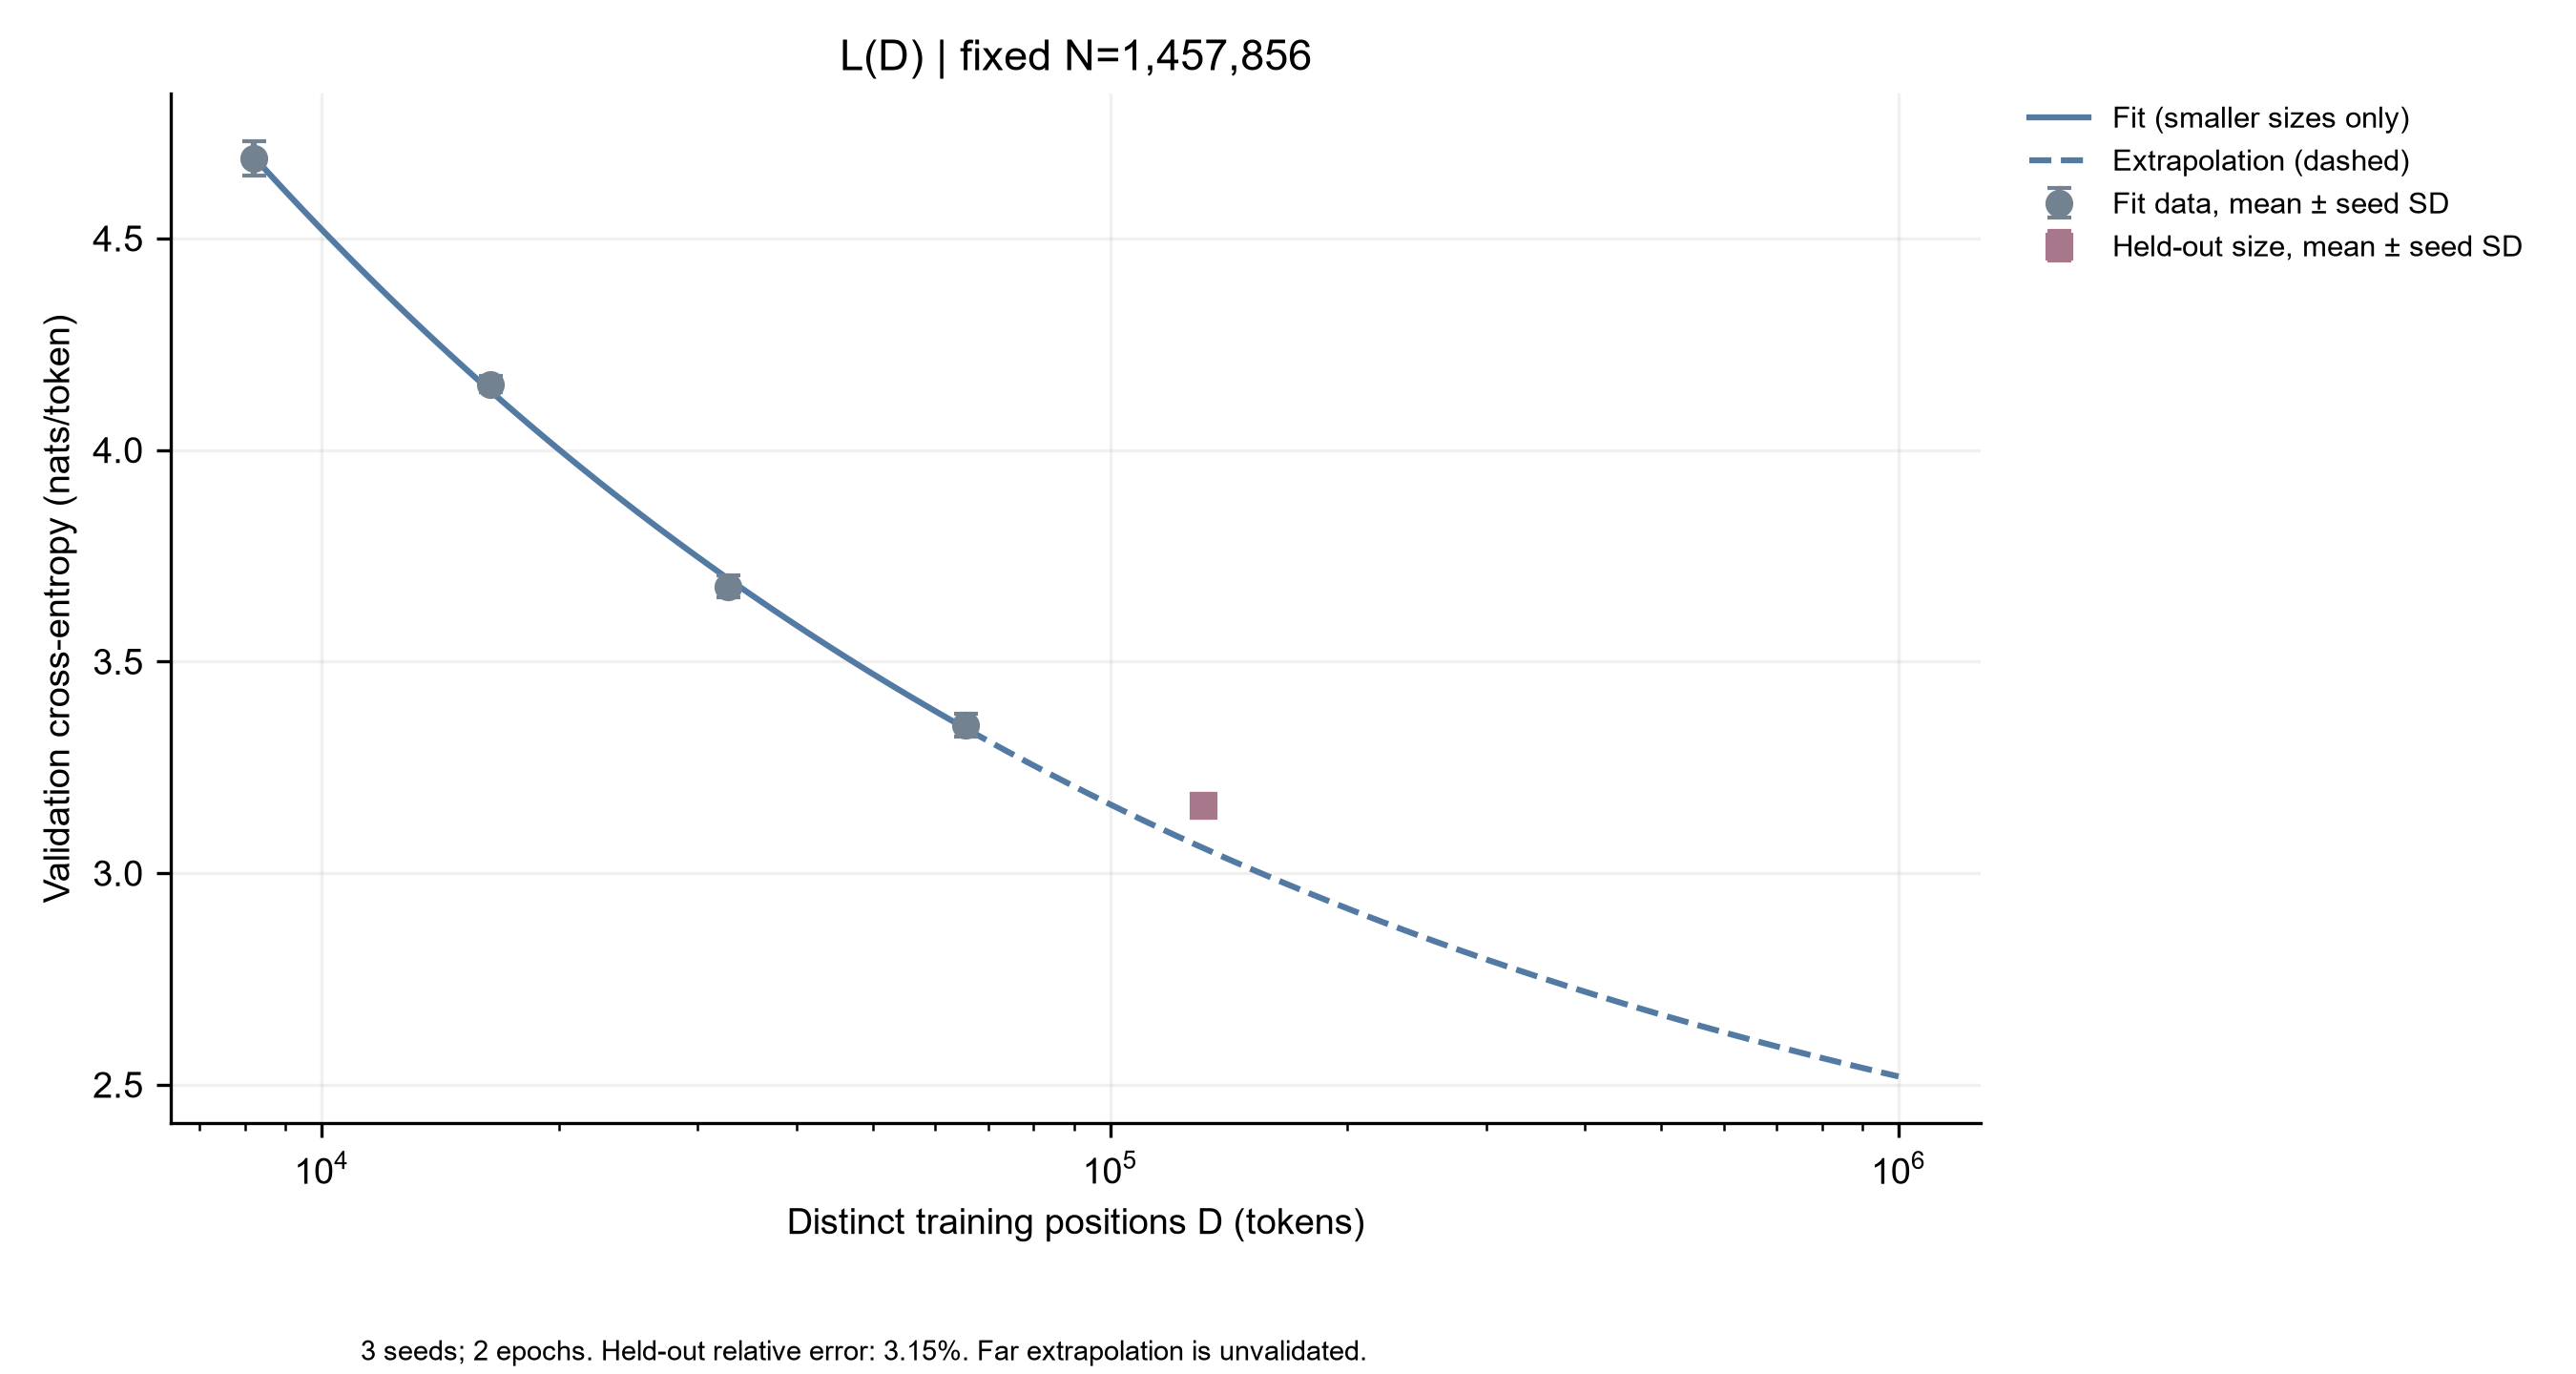

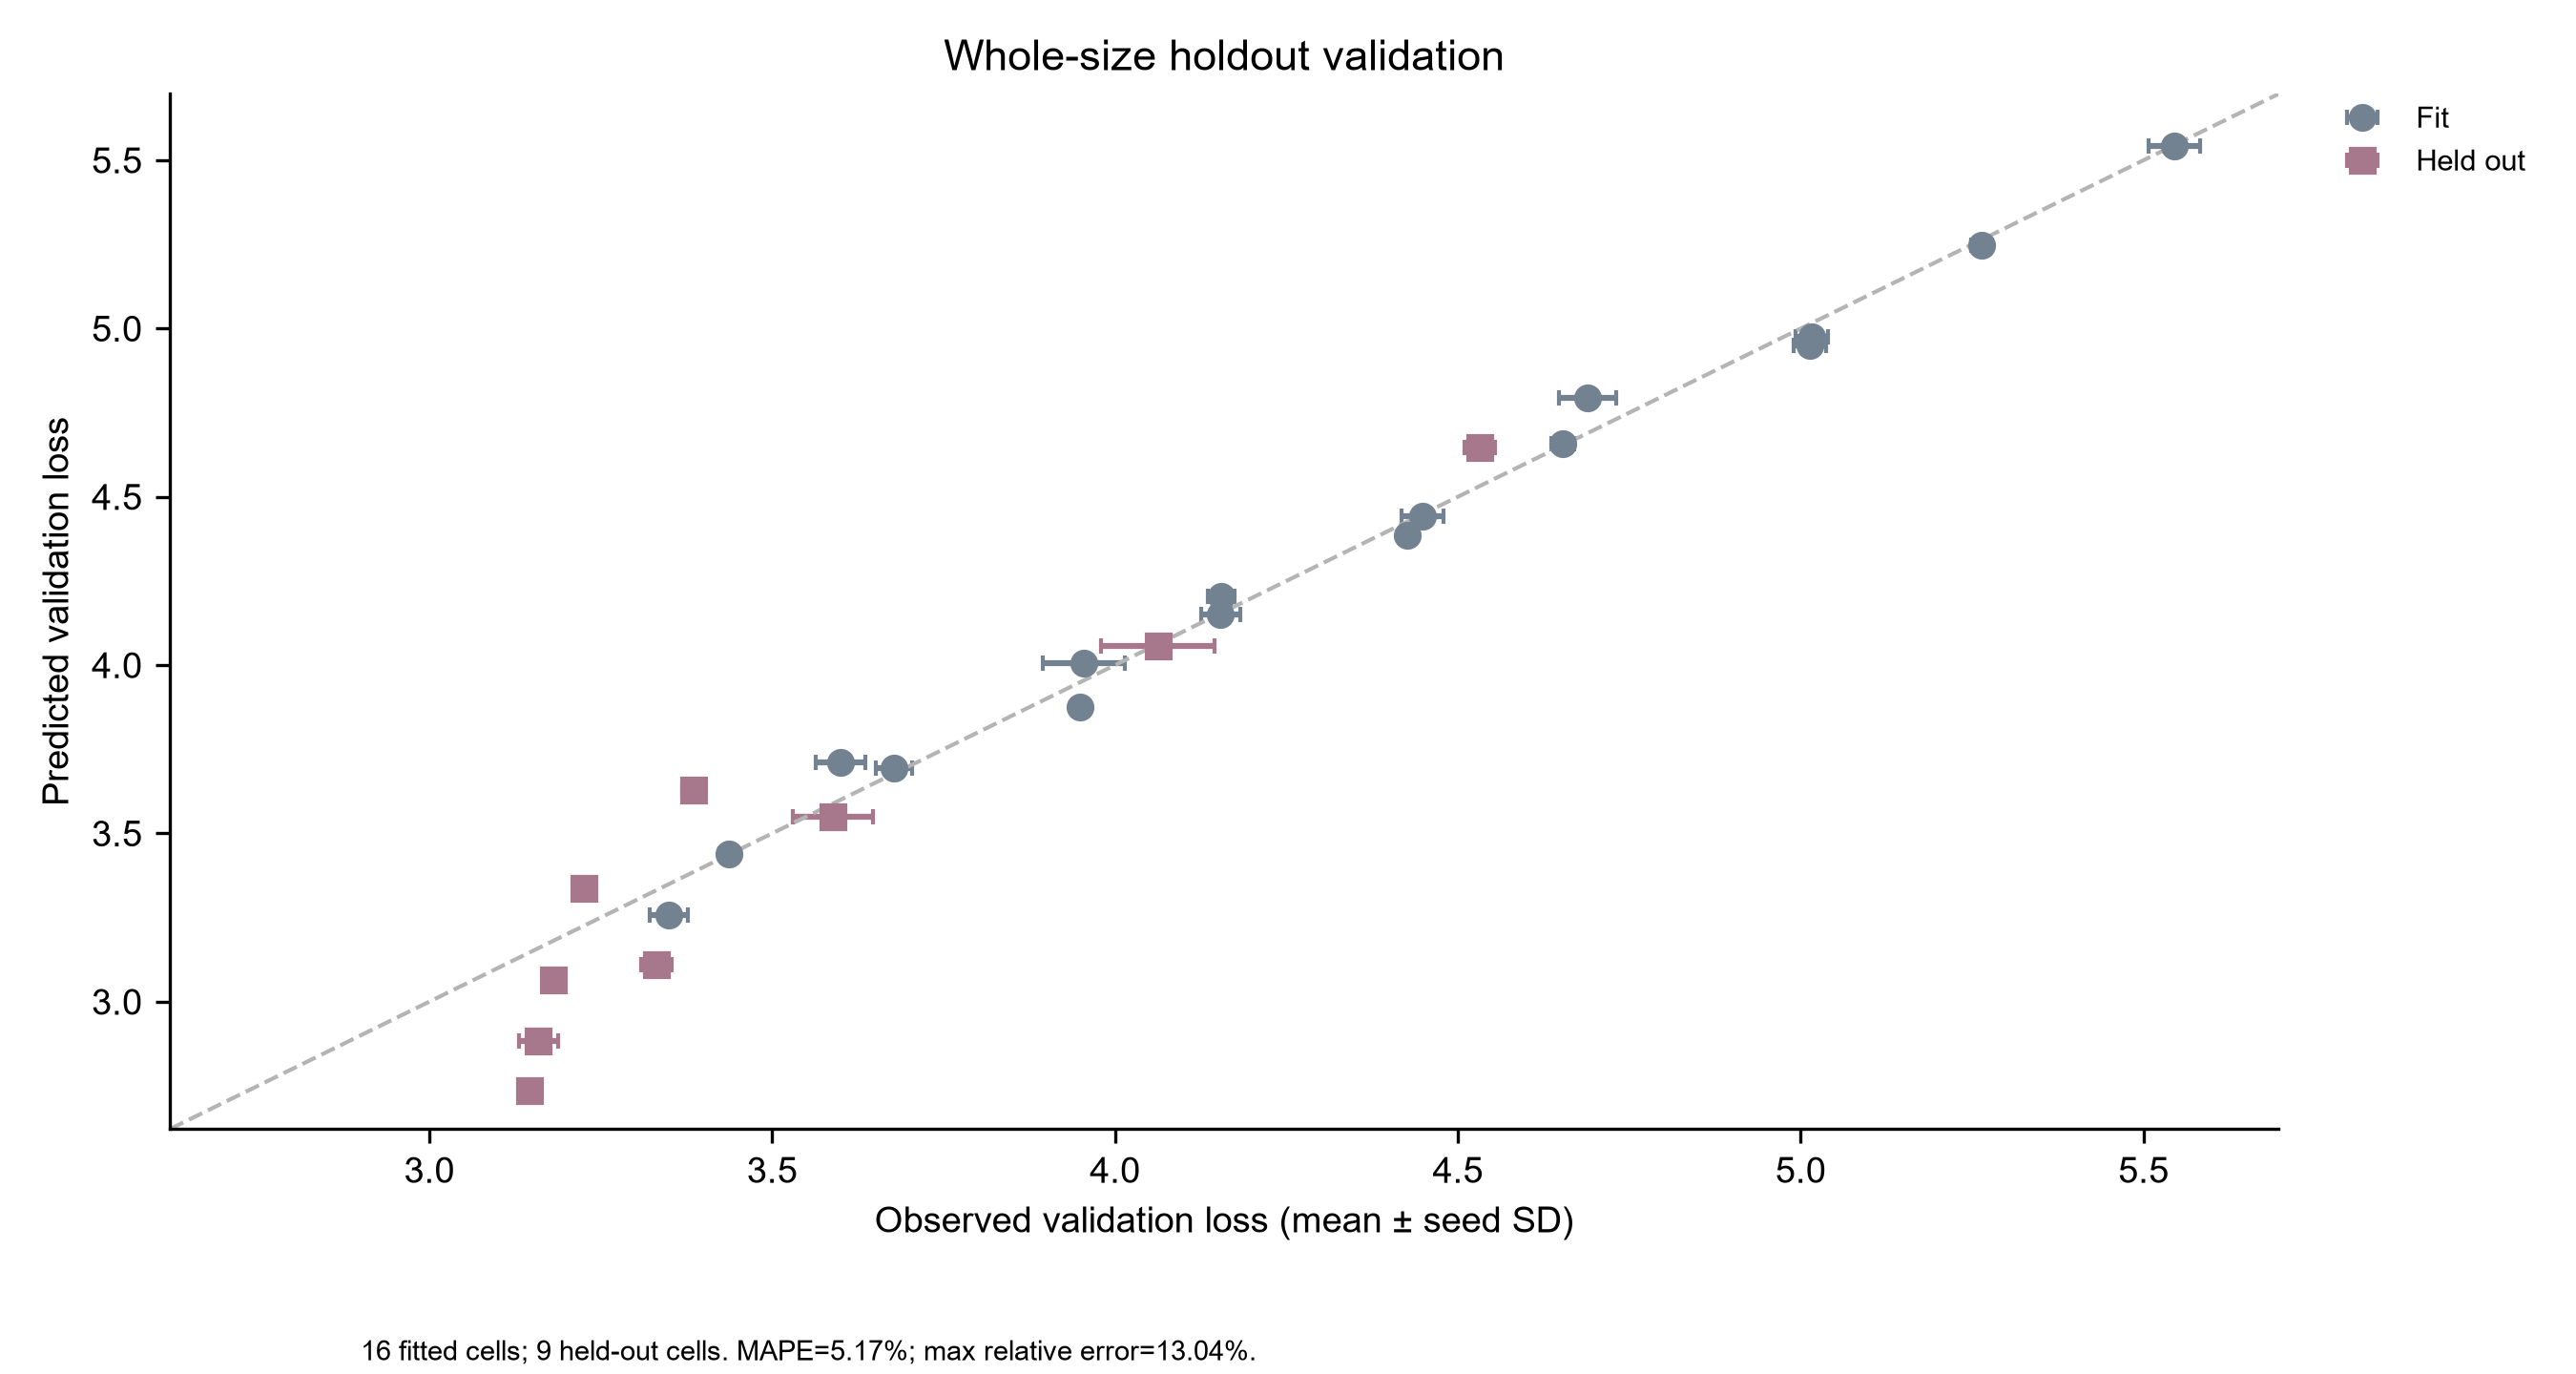

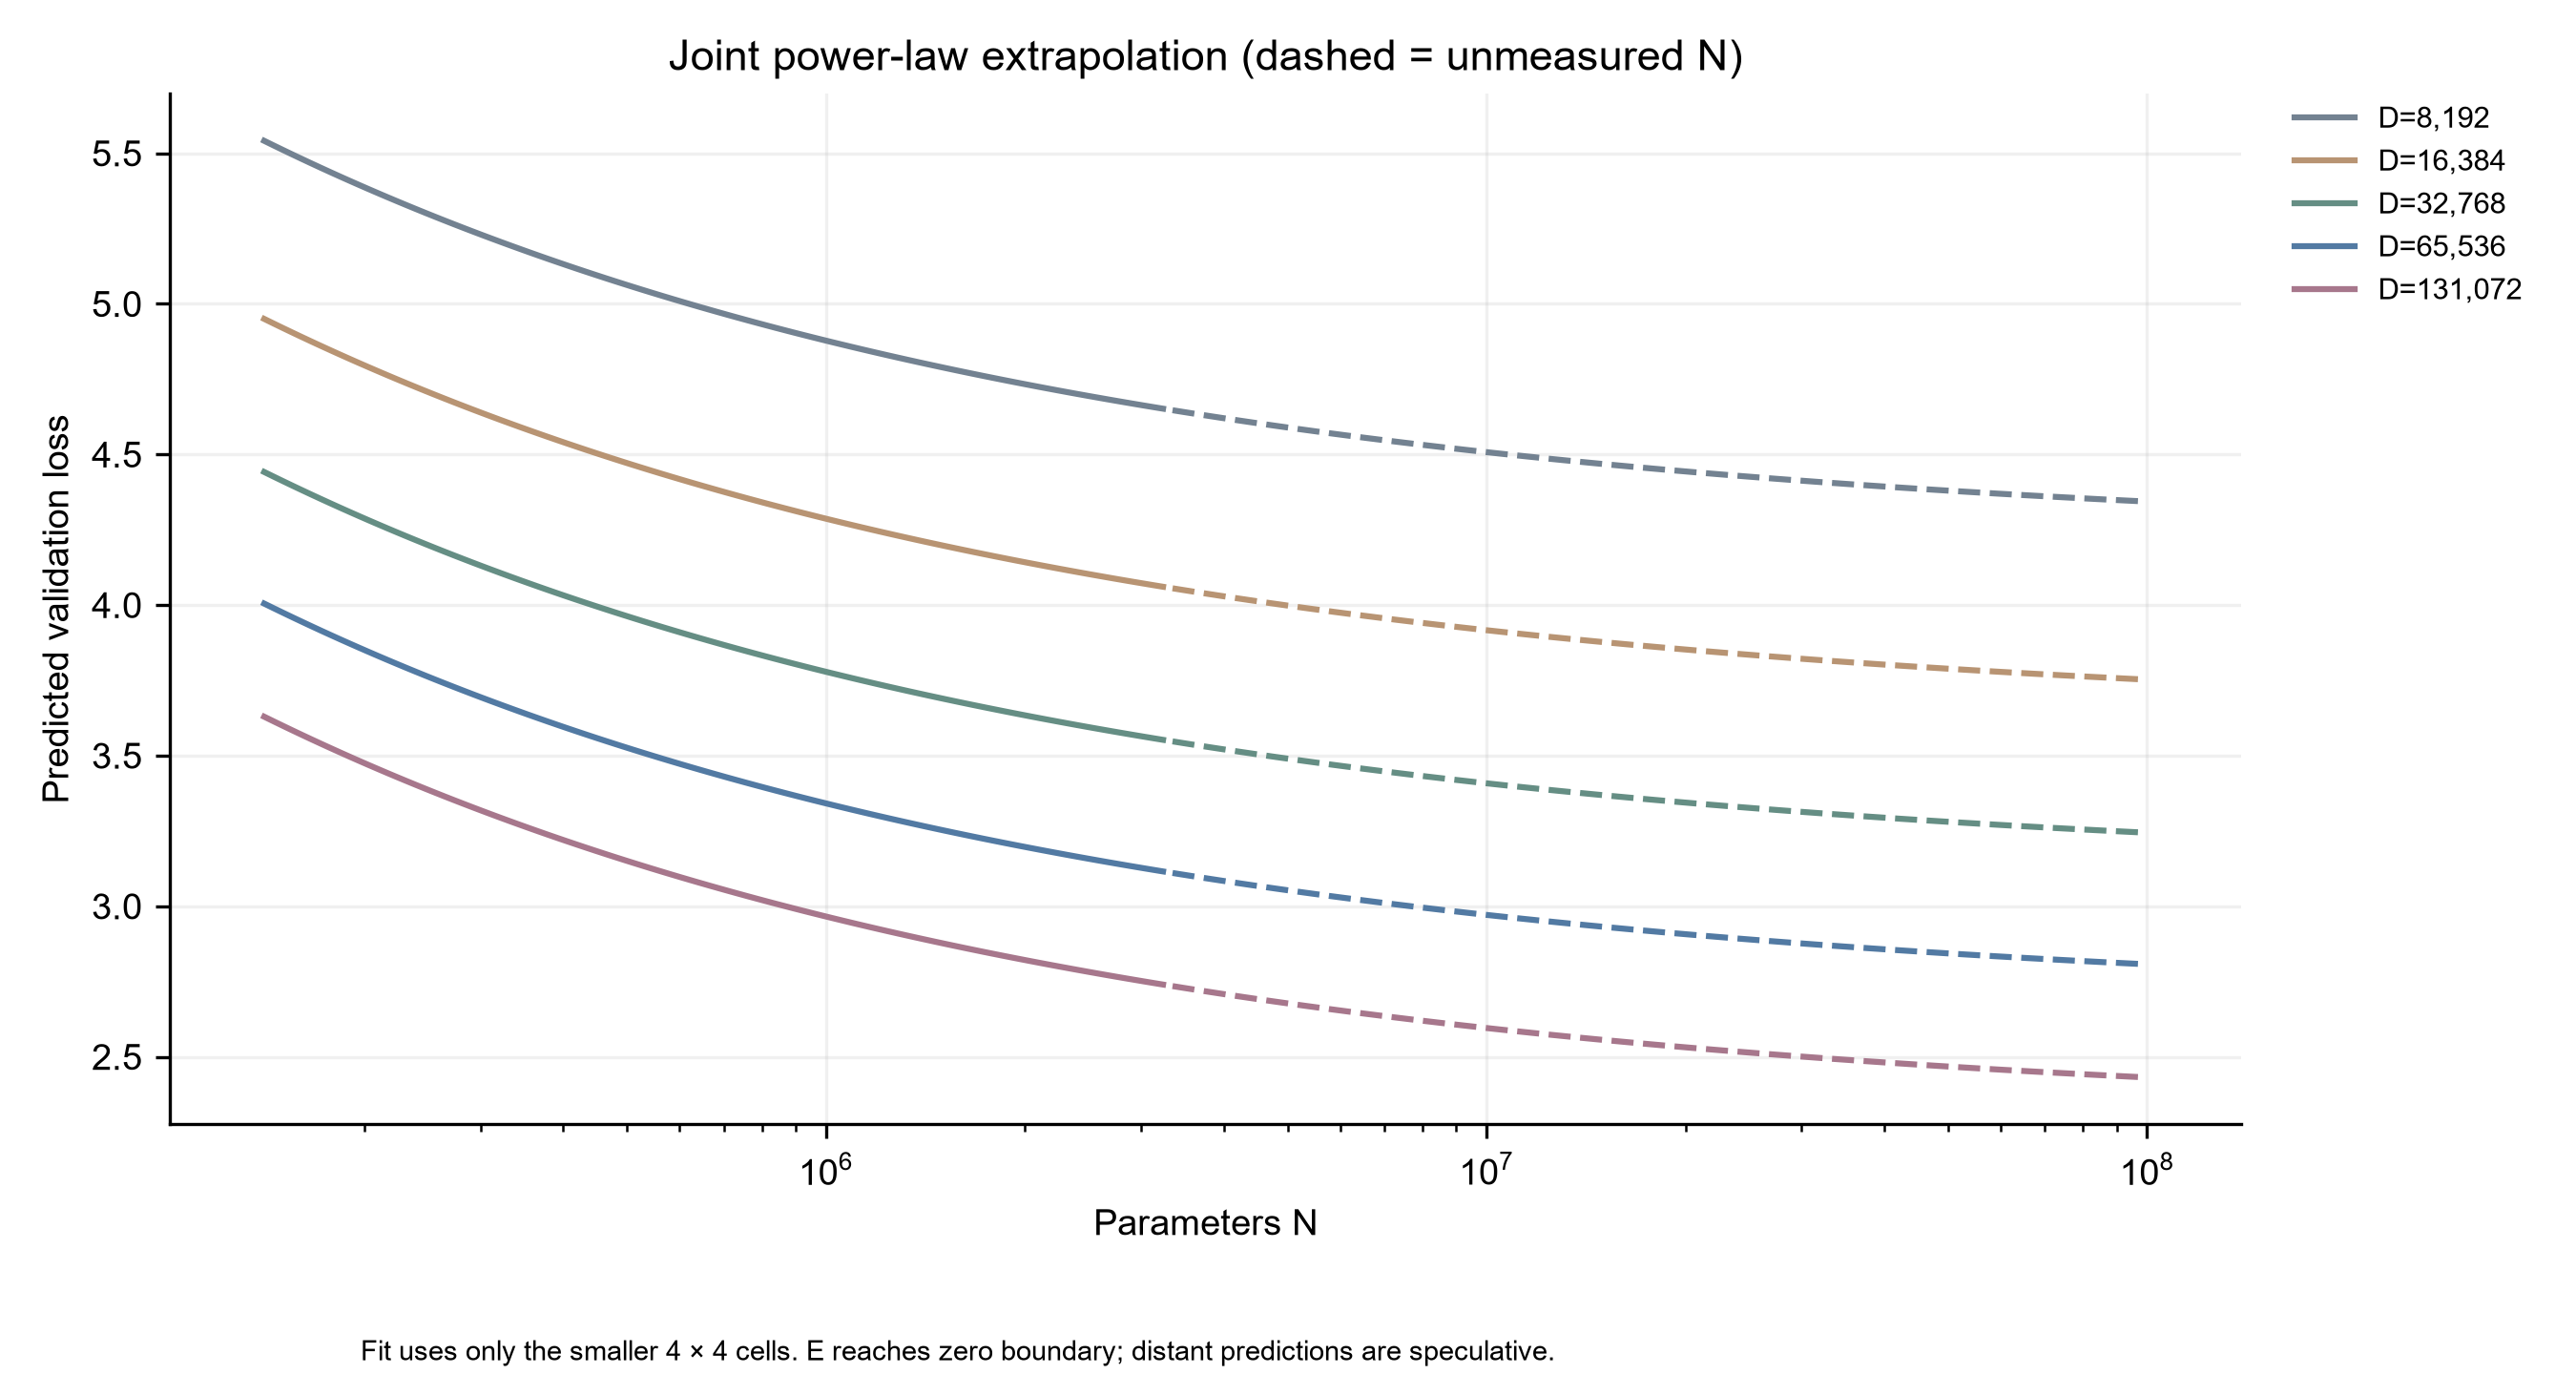

In [3]:
display({k:result[k] for k in ['training_cells','held_out_cells','fit_rmse','holdout_mape','holdout_max_relative_error','local_mape_gate_passed']})
from plot_results import scaling_plots
scaling_plots()
for name in ['scaling_N','scaling_D','scaling_holdout','scaling_law']:
    display(Image(filename=str(STAGE/'curves'/f'{name}.png')))

## 0.1B extrapolation is a hypothesis

This is a distant extrapolation on a single literary corpus after only two training epochs. No 0.1B model was trained with the same experiment protocol. The 95% bootstrap interval includes seed variation only; it excludes model misspecification and domain shift. It must not be used as a reliable performance forecast.

In [4]:
display(result['speculative_0_1b'])
display(result['limitations'])

{'N': 100000000,
 'D': 1000000,
 'predicted_loss': 1.60750228969505,
 'seed_bootstrap_95pct': [1.568437265090281, 1.6690786162411104],
 'validated': False,
 'reason': 'Far outside measured N,D; no 0.1B checkpoint was trained under this protocol. Local MAPE cannot bound this error.'}

['Only 2 epochs, not convergence/compute-optimal scaling',
 'Nested contiguous subsets confound data amount with composition and optimizer steps',
 'Single literary corpus and one fixed validation segment',
 'Finite-size loss floor and exponents can be weakly identifiable',
 'Bootstrap captures seed variation, not corpus or model-family uncertainty']

## Reproduce

From repository root: `python 04_systems_scaling/scripts/run_scaling.py`, `python 04_systems_scaling/scripts/fit_scaling.py`, `python 04_systems_scaling/scripts/plot_results.py`. This notebook refits archived measurements and redraws figures without retraining. Seeds and all hyperparameters are in `../config.json`.